# Meta cells with bixverse

*Python port of the R vignette [Meta cells with bixverse](https://gregorlueg.github.io/bixverse/articles/meta_cells.html). Original author: Gregor Lueg.*

## Intro

Meta cells are small groups of transcriptionally similar cells aggregated into
a single representative profile. The motivation is twofold: firstly, single
cell counts are sparse and noisy, and many downstream methods (correlation
networks, GRN inference, archetype-based modelling) behave poorly on raw
single cell data. Aggregating into meta cells reduces sparsity while
preserving the heterogeneity that bulk pseudo-replicates would average out.
Secondly, they reduce the computational burden substantially.

`bixverse` provides four meta cell algorithms with different underlying ideas:

- **hdWGCNA-style meta cells**
  ([Morabito, et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498))
  iterate over a kNN graph, picking seed cells and aggregating their
  neighbours, with a constraint on how many cells two meta cells are allowed
  to share. Simple, fast and reasonably effective. Works directly on a kNN
  graph.
- **SEACells**
  ([Persad, et al., 2023](https://doi.org/10.1038/s41587-023-01716-9)) uses
  kernel archetypal analysis. The algorithm finds a set of archetypes (the
  SEACells) such that every cell can be expressed as a convex combination of
  nearby archetypes. Tends to produce purer aggregations but is the most
  computationally expensive of the four.
- **SuperCells**
  ([Bilous, et al., 2022](https://doi.org/10.1186/s12859-022-04861-1))
  applies the walktrap community detection algorithm to the kNN graph and
  treats each community as a meta cell. Granularity is controlled indirectly
  through a graining factor (the average number of cells per meta cell).
- **MetaCells2**
  ([Ben-Kiki, et al., 2022](https://doi.org/10.1186/s13059-022-02667-1))
  works on the raw counts and builds its own similarity graph, no embedding
  or kNN needed. It aims for meta cells of a target size and UMI count,
  splits the cells into piles, and leaves cells it cannot place convincingly
  unassigned.

One implementation detail worth flagging upfront. The `SingleCells` class
keeps counts on disk in DuckDB and binary Rust-based files and streams them
in as needed. The `MetaCells` class does not. After aggregation the count
matrix is small enough to hold entirely in memory as a sparse matrix, and all
downstream operations (HVG, PCA, neighbours, clustering, embeddings) run
against this in-memory representation (most of the code still runs in Rust
nonetheless). Practically that means the meta cell pipeline is substantially
faster than the equivalent operations on the parent `SingleCells` object for
two reasons: data is already in memory and more importantly, it is simply
less data.

In [1]:
import tempfile
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import (
    BtMetacellsParams,
    NeighboursParams,
    NmfConsensusParams,
    ScenicParams,
    ScenicRandomForestDefaults,
    SeacellsParams,
    SupercellParams,
)

## Preparing the single cell data

We use the same CD34 cells from the
[SEACells vignette](https://github.com/dpeerlab/SEACells/blob/main/notebooks/SEACell_computation.ipynb)
to set up the parent `SingleCells` object: load (QC not needed, it's already
filtered data), HVG selection, PCA, kNN graph. We can use the provided cell
type labels to check purity.

In [2]:
cd34_path = bv.io.download_cd34_data()

tempdir_cd34 = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(Path(tempdir_cd34.name) / "cd34", cd34_path)

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpofnckbzd/cd34',
  cells=6881 (kept 6881), genes=12464,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

HVG detection, PCA and kNN (+ sNN) generation.

In [3]:
bv.pp.find_hvg(sc, hvg_no=2000)

bv.pp.calculate_pca(sc, no_pcs=30)

bv.graph.find_neighbours(
    sc,
    neighbours_params=NeighboursParams(ann_dist="euclidean", knn_method="kmknn"),
)

# we need the kNN graph for the diffusion maps
knn = sc.cache.knn

## Generating meta cells

All four generators take a `SingleCells` object, read counts from the binary
files as needed, and return a `MetaCells` object. They share a common output
structure: an obs table with one row per meta cell (recording which original
cells went into it), a var table mirrored from the parent object, and an
in-memory sparse count matrix.

### hdWGCNA-style (bootstrapped metacells)

The hdWGCNA-style algorithm reuses the kNN graph already on the object. The
two parameters that matter most are `target_no_metacells` and `max_shared`,
which controls how many cells two meta cells may have in common. The original
paper uses 1000 meta cells, but we want to also compare the different metrics
downstream, so we will set it to 250. We also recalculate the kNN graph with
larger k, to include more cells per given meta cell.

In [4]:
hdwgcna = bv.metacells.generate_bt_meta_cells(
    sc,
    params=BtMetacellsParams(target_no_metacells=250, k=25),
    # regenerate the kNN graph with 25 neighbours
    regenerate_knn=True,
    verbose=True,
)

hdwgcna

Identifying meta cells.
Aggregating meta cells.


MetaCells(
  method=meta_cells_hdwgcna, merged=False,
  meta_cells=250, genes=12464,
  cells_aggregated=3993, source_obs_rows=6881,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, residuals=False,
  stale=none
)

Importantly, not all cells HAVE to be assigned to a meta cell and cells can
occur in several meta cells at once. A number of cells remains unassigned and
each meta cell contains self + neighbours, i.e., 26 (self + `k = 25`)
original cells. How often do the cells occur... ?

2888 of 6881 cells unassigned


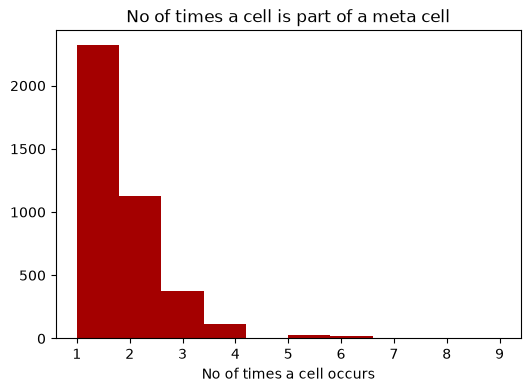

In [5]:
a = hdwgcna.original_assignment
print(f"{a.n_unassigned} of {a.n_cells} cells unassigned")

no_duplicated_cells = (
    hdwgcna.cell_assignments().group_by("cell_idx").len()["len"].to_numpy()
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(no_duplicated_cells, bins=10, color=bv.pl.bx_colors("main", n=1)[0])
ax.set_xlabel("No of times a cell occurs")
ax.set_title("No of times a cell is part of a meta cell")
plt.show()

Some of the cells are indeed shared across meta cells. We add the diffusion
coordinates to this one for later analysis.

In [6]:
bv.metacells.calc_diffusion_coordinates(hdwgcna, knn)

### SEACells

SEACells operates on the PCA embedding (or any batch corrected embedding) and
the kNN graph and runs an iterative kernel archetypal analysis. `n_sea_cells`
sets the number of archetypes; `min_iter`/`max_iter` bound the optimisation;
`convergence_epsilon` sets the early stopping threshold relative to the
initial RSS. The algorithm was aggressively optimised to be faster. With
`pruning=True` (default) small values are set to zero, removing basically
dust and accelerating the calculations substantially. The rule of thumb by
the authors is one SEACell per 75 cells, i.e., 90 SEACells for this
experiment. We will set this higher here to 250 to make this a bit more
comparable with the other methods...

In [7]:
seacells = bv.metacells.generate_seacells(
    sc,
    SeacellsParams(n_sea_cells=250, min_iter=10, convergence_epsilon=0.001),
    verbose=True,
)

seacells

Computing adaptive bandwidth RBF kernel...
Built kernel with 160_077 non-zeros
Computing diffusion maps for waypoint initialisation...
Selecting 227 cells from waypoint initialisation.
Initialising residual matrix using greedy column selection
Selecting 23 cells from greedy initialisation.
Initialising A and B matrices...


Initial RSS: 144.214905
Convergence threshold: 0.144215


Iteration 1: RSS = 141.112671, Time = 0.49s


Iteration 2: RSS = 136.982239, Time = 0.67s


Iteration 3: RSS = 135.047287, Time = 0.60s


Iteration 4: RSS = 133.938187, Time = 0.58s


... (4 outputs left out)

Iteration 9: RSS = 131.607452, Time = 0.70s


Iteration 10: RSS = 131.445267, Time = 0.66s


Iteration 11: RSS = 131.322037, Time = 0.52s
Converged after 11 iterations!
Aggregating meta cells.
SEACells found in: 6.97s


MetaCells(
  method=seacell, merged=False,
  meta_cells=250, genes=12464,
  cells_aggregated=6881, source_obs_rows=6881,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, residuals=False,
  stale=none
)

Each SEACell can contain a varying number of original cells.

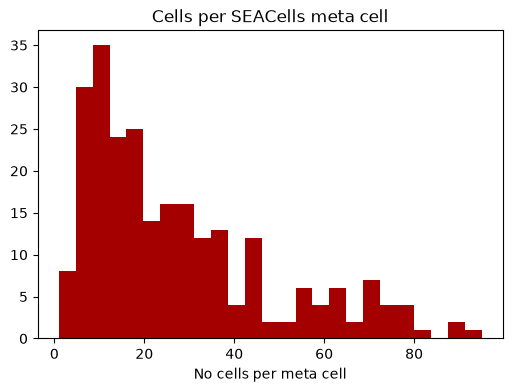

In [8]:
def cells_per_meta_cell(mc: bv.metacells.MetaCells) -> np.ndarray:
    return mc.obs()["original_cell_idx"].list.len().to_numpy()


fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(cells_per_meta_cell(seacells), bins=25, color=bv.pl.bx_colors("main", n=1)[0])
ax.set_xlabel("No cells per meta cell")
ax.set_title("Cells per SEACells meta cell")
plt.show()

We will also add the diffusion coordinates to this one.

In [9]:
bv.metacells.calc_diffusion_coordinates(seacells, knn)

#### SEACells on large data

SEACells is infamous for being very slow and difficult to run on larger data
sets. Most of the hot path has been rewritten in `bixverse`, which is what
makes the algorithm feasible beyond a few tens of thousands of cells:

1. The initialisation is the part of the original algorithm that scales the
   worst. The greedy column subset selection needs a full `K^2` column for
   every candidate cell, which is `O(N^2)` and simply will not finish on
   millions of cells. `bixverse` therefore switches strategy by size: above
   `greedy_threshold` (20,000 cells by default) it drops the greedy top-up
   and samples the archetypes at random, which is effectively free. When a
   better-than-random start is wanted but the greedy pass is still out of
   reach, setting `n_landmarks` turns on a Nyström route: a small set of
   density-weighted landmarks is chosen (5 to 10 times `n_sea_cells` is a
   sensible range), the diffusion operator is built and eigendecomposed on
   those landmarks alone, and the multiscale embedding is carried to all
   cells via a Nyström extension before the usual max-min waypoint sampling.
   The eigendecomposition stays at landmark scale `L x L` instead of `N x N`.
2. The optimisation loop itself runs in bounded memory. `K^2` is never
   formed; every `K^2 X` term is evaluated as `K (K X)`, so memory stays
   bounded by the number of non-zeros in `K` rather than `N^2`. Neither
   Frank-Wolfe gradient is ever materialised. The A update runs cell-major: a
   column of `A` is a convex combination of at most `max_fw_iters` one-hot
   atoms, so the solver carries `(index, weight)` pairs and patches the
   gradient with rank-1 corrections instead of rebuilding it from the sparse
   `A` on every iteration. The argmin over the two gradient terms is fused
   and runs on SIMD (NEON on Apple Silicon, SSE2, AVX-2 or AVX-512 picked at
   runtime on x86). The B update walks one gradient column per archetype in
   the same spirit. Everything is chunked across rayon threads.
3. `K^2 B` is the one product the inner loop needs on every single
   iteration, so it is cached rather than recomputed. A Frank-Wolfe step
   changes `B` by a rank-k update, and the matching change to `K^2 B` is the
   same scaling plus one weighted column of `K^2` per archetype; the pruning
   corrections fold into the same delta. The update is exact, and a full
   recompute still runs every eight iterations to bound floating point drift
   and the sparsity pattern. The B loop stops early once the relative
   Frank-Wolfe duality gap drops below `1e-3`.
4. `pruning` is on by default and should stay on. The Frank-Wolfe updates
   only ever add atoms, so without pruning the non-zeros in `A` and `B` climb
   monotonically across the whole fit and the time per iteration keeps rising
   instead of settling. The accuracy cost sits in `pruning_threshold`, not in
   the flag. Keep it below the smallest weight the schedule can produce,
   `2 / (T (T + 1))` for `T = max_fw_iters`; above that you start deleting
   live mass and shift the solution. The default `1e-7` removes numerical
   dust only.
5. The RSS for the convergence check never materialises the `N x N`
   reconstruction `K B A`. The squared residual is expanded with the trace
   identity and evaluated through cyclic reordering, so every intermediate is
   at most `N x k` or `k x k`. Same Frobenius norm, just without the dense
   reconstruction.

Most of that is automatic. The knobs you actually reach for on large data are
`greedy_threshold` and `n_landmarks` for the initialisation, and
`pruning`/`pruning_threshold` for the loop. Together they are what made it
possible to run a million cells locally, which the original implementation
cannot do.

### SuperCells

SuperCells runs walktrap on the kNN graph. The number of meta cells is set
indirectly through `graining_factor`: with a factor of 30 over ~6800 cells you
should get roughly ~230 meta cells. The kernel-based version of SuperCells 2.0
from [Hérault et al.](https://www.biorxiv.org/content/10.64898/2026.02.19.706848v1)
is on by default. (The multi-modal versions are still to come. Watch the
space...)

In [10]:
supercells = bv.metacells.generate_supercells(
    sc,
    params=SupercellParams(graining_factor=30),
    verbose=True,
)

supercells

Running SuperCell with Walktrap
Using the kernel approach like in SuperCell 2.0


Aggregating meta cells.


MetaCells(
  method=supercells, merged=False,
  meta_cells=230, genes=12464,
  cells_aggregated=6881, source_obs_rows=6881,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, residuals=False,
  stale=none
)

The number of cells per SuperCell:

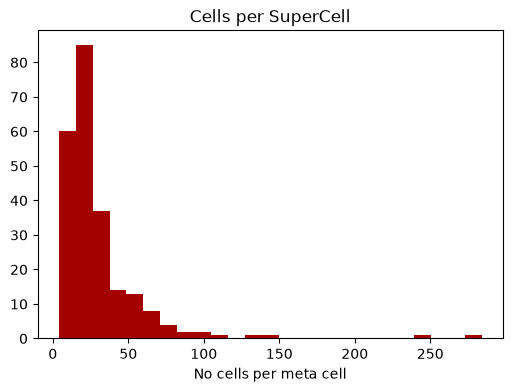

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(cells_per_meta_cell(supercells), bins=25, color=bv.pl.bx_colors("main", n=1)[0])
ax.set_xlabel("No cells per meta cell")
ax.set_title("Cells per SuperCell")
plt.show()

Similar to SEACells, we get a gradient here.

In [12]:
bv.metacells.calc_diffusion_coordinates(supercells, knn)

#### SuperCells on large data

SuperCell is already far cheaper than SEACells on large data: there is no
archetypal analysis, just Walktrap community detection on the kNN graph. The
one part that does not scale naively is the random-walk representation.
`compute_walk_probabilities()` within the Rust code gives every cell a sparse
vector of landing probabilities for a `walk_length`-step walk; on a
well-connected graph these vectors spread to touch a large fraction of cells
after only a few steps, so the store drifts towards dense and memory grows as
`O(n x support)`.

`max_support` caps this. With `max_support = k` each initial walk vector keeps
only its `k` largest entries (the dropped tail holds negligible walk mass),
bounding the store at roughly `k x n` regardless of how far the walks spread.
This makes the run an approximation: the Ward merge criterion is driven by
distances between walk vectors, and truncating them can shift the merge order
slightly, so you may get marginally different communities than the exact run.
With `max_support=None` (the default) the walks are kept exact. Beyond saving
memory, a smaller `k` also speeds up every distance and merge operation, since
both are linear in the support.

```python
supercells_large = bv.metacells.generate_supercells(
    sc,
    params=SupercellParams(
        graining_factor=30,
        max_support=256,  # would bound the walk vectors to 256
    ),
    verbose=True,
)
```

### MetaCells2

MetaCells2 is the odd one out. It never touches the PCA or the kNN graph from
above: it downsamples the raw counts per pile, picks its own feature genes,
builds a balanced kNN graph on their correlations and partitions that with
simulated annealing. Cells that look deviant within their candidate meta cell
get pulled out and re-run, and whatever still does not fit is left
unassigned. The size knobs are `target_metacell_size` (cells) and
`target_metacell_umis` in `Metacells2Params`; the defaults (48 cells, 160k
UMIs) are upstream's.

In [13]:
metacells2 = bv.metacells.generate_metacells2(sc, verbose=True)

metacells2

Divide and conquer over 6881 cells, target pile size 8000


 level 1: 1 piles of 6881 elements, 205 metacells so far
 level 2: 1 piles of 136 elements, 209 metacells so far


MetaCells(
  method=metacells2, merged=False,
  meta_cells=209, genes=12464,
  cells_aggregated=6846, source_obs_rows=6881,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, residuals=False,
  stale=none
)

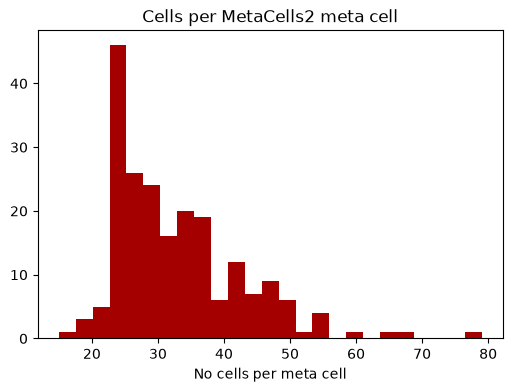

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(cells_per_meta_cell(metacells2), bins=25, color=bv.pl.bx_colors("main", n=1)[0])
ax.set_xlabel("No cells per meta cell")
ax.set_title("Cells per MetaCells2 meta cell")
plt.show()

The outliers and a few per-cell details sit in `other_data`: whether the
cell's candidate got dissolved, in which outlier round it was placed and, if
any, its rare gene module.

In [15]:
mc2_cell_info = metacells2.other_data["cell_info"]

print(f"{metacells2.original_assignment.n_unassigned} cells unassigned")

mc2_cell_info.group_by("level", "dissolved").len().sort("level", "dissolved")

35 cells unassigned


level,dissolved,len
i32,bool,u32
1,false,6745
2,false,133
2,true,3


In [16]:
bv.metacells.calc_diffusion_coordinates(metacells2, knn)

#### MetaCells2 on large data

The divide and conquer part is what makes this scale. Cells get split into
piles of 8k to 24k cells (`Metacells2DacParams`), every pile is processed on
its own, and the resulting meta cells are grouped into piles of similar meta
cells for a second pass, so rare states that got spread across random piles
end up together. Each pile holds two dense `pile x pile` matrices, so memory
is bounded by the pile size, not the data size.

Before any of that, rare gene modules are detected: genes expressed in at
most 0.1% of the cells that co-occur. Their cells get piled separately, so a
rare population of a few dozen cells does not get diluted across piles. On
small data like this the step finds nothing, which is what upstream does too.
Switch it off with `rare_gene_modules=False`.

`max_parallel_piles` trades memory for speed. Each extra pile in flight costs
another two dense matrices.

```python
from bixverse.params import Metacells2DacParams

metacells2_large = bv.metacells.generate_metacells2(
    sc,
    dac_params=Metacells2DacParams(max_parallel_piles=4),
    verbose=True,
)
```

## Metrics

### Purity

A simple sanity check is to ask, for each meta cell, what fraction of its
constituent cells share the same underlying label. We use the cell type
labels that ship with the data as a proxy for cell type identity. The labels
themselves are imperfect, so absolute numbers should be read with that
caveat, but relative differences between methods are reasonably indicative.

In [17]:
# memberships are positions in the full obs table, so the labels come from the
# unfiltered obs (here every cell is kept anyway)
cell_labels = sc.obs(cols=["celltype"])["celltype"].cast(pl.String).to_list()

meta_cells = {
    "hdWGCNA": hdwgcna,
    "SEACells": seacells,
    "SuperCells": supercells,
    "MetaCells2": metacells2,
}

for mc in meta_cells.values():
    bv.metacells.calc_meta_cell_purity(mc, cell_labels)

purity_df = pl.concat(
    [
        mc.obs(cols=["mc_purity"]).select(
            pl.lit(method).alias("method"), pl.col("mc_purity").alias("purity")
        )
        for method, mc in meta_cells.items()
    ]
)

purity_df.group_by("method", maintain_order=True).agg(
    mean=pl.col("purity").mean(), median=pl.col("purity").median()
)

method,mean,median
str,f64,f64
"""hdWGCNA""",0.883077,0.961538
"""SEACells""",0.903936,1.0
"""SuperCells""",0.899453,0.993338
"""MetaCells2""",0.86975,0.931818


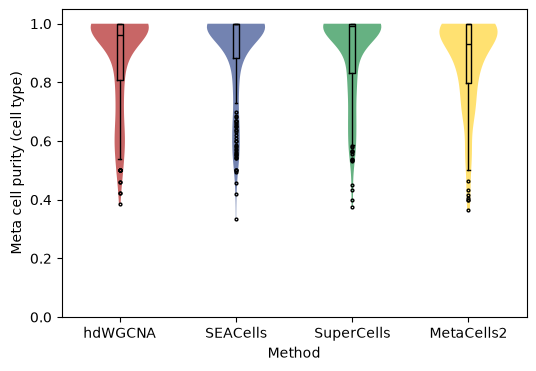

In [18]:
def violin_by_method(
    df: pl.DataFrame, value: str, ylabel: str, ax: plt.Axes | None = None
) -> plt.Axes:
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    methods = list(meta_cells)
    data = [df.filter(pl.col("method") == m)[value].to_numpy() for m in methods]
    parts = ax.violinplot(data, showextrema=False)
    for body, colour in zip(
        parts["bodies"], bv.pl.bx_colors("main", n=len(methods)), strict=True
    ):
        body.set_facecolor(colour)
        body.set_alpha(0.6)
    ax.boxplot(
        data,
        widths=0.05,
        flierprops={"markersize": 2},
        medianprops={"color": "black"},
    )
    ax.set_xticks(range(1, len(methods) + 1), methods)
    ax.set_xlabel("Method")
    ax.set_ylabel(ylabel)
    return ax


ax = violin_by_method(purity_df, "purity", "Meta cell purity (cell type)")
ax.set_ylim(0, 1.05)
plt.show()

In terms of cell type purity, the methods are basically the same. Potentially
more interesting is their behaviour in the manifold, see below...

### Manifold regions

We called `calc_diffusion_coordinates()` with the kNN graph on the data. This
tells us which parts of the manifold are being sampled here, e.g. high,
medium or low density regions (based on the diffusion map and the distance to
the 150th neighbour within that). This gives an idea how many rare cell
states the meta cells capture.

In [19]:
regions = ["high", "mid", "low"]
region_colours = {"high": "#2c2d54", "mid": "#969bc7", "low": "#6f9954"}

region_df = (
    pl.concat(
        [
            mc.obs(cols=["density_region"]).select(
                pl.lit(method).alias("method"),
                pl.col("density_region").alias("region"),
            )
            for method, mc in meta_cells.items()
        ]
    )
    .group_by("method", "region")
    .len()
    .with_columns(proportion=pl.col("len") / pl.col("len").sum().over("method"))
)

region_df.pivot(on="region", index="method", values="proportion").select(
    "method", *regions
)

method,high,mid,low
str,f64,f64,f64
"""SEACells""",0.136,0.352,0.512
"""SuperCells""",0.130435,0.452174,0.417391
"""hdWGCNA""",0.236,0.536,0.228
"""MetaCells2""",0.30622,0.4689,0.22488


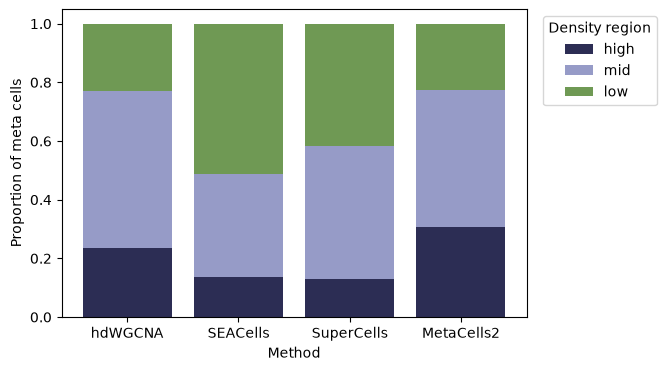

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
methods = list(meta_cells)
bottom = np.zeros(len(methods))
for region in regions:
    props = np.array(
        [
            region_df.filter((pl.col("method") == m) & (pl.col("region") == region))[
                "proportion"
            ].sum()
            for m in methods
        ]
    )
    ax.bar(methods, props, bottom=bottom, color=region_colours[region], label=region)
    bottom += props
ax.set_xlabel("Method")
ax.set_ylabel("Proportion of meta cells")
ax.legend(title="Density region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

This is one of the most important differences between the methods. hdWGCNA
disproportionally samples the medium density regions of the manifold and is
basically proportion-based. SEACells on the other hand generates meta cells
that capture sparse (more heterogeneous) regions of the manifold. SuperCells
sits between the two methods. MetaCells2 looks a lot like hdWGCNA here, if
anything with a stronger pull towards the dense regions.

### Compactness and separation

We can also assess other metrics on the manifold representation. Compactness
(how close are the cells within a given meta cell to the centroid) and
separation (how far is the closest centroid). The first gives an (unbiased)
indication of purity; the latter of diversity captured in the manifold. We
can do this trivially via:

In [21]:
for mc in meta_cells.values():
    bv.metacells.calc_manifold_metrics(mc)

A long frame for the plots and the summaries:

In [22]:
metrics_df = pl.concat(
    [
        mc.obs(cols=["separation", "compactness", "density_region"]).select(
            pl.lit(method).alias("method"),
            "separation",
            "compactness",
            pl.col("density_region").cast(pl.Enum(regions)).alias("region"),
        )
        for method, mc in meta_cells.items()
    ]
)

summary_cols = [
    pl.col("separation").mean().alias("mean_separation"),
    pl.col("separation").median().alias("median_separation"),
    pl.col("compactness").mean().alias("mean_compactness"),
    pl.col("compactness").median().alias("median_compactness"),
]

metrics_df.group_by("method", maintain_order=True).agg(summary_cols)

method,mean_separation,median_separation,mean_compactness,median_compactness
str,f32,f32,f32,f32
"""hdWGCNA""",0.233997,0.169376,0.040876,0.02296
"""SEACells""",0.313446,0.270859,0.04773,0.023736
"""SuperCells""",0.320707,0.272672,0.033085,0.018128
"""MetaCells2""",0.268909,0.155765,0.074056,0.032496


Some differences are visible here (lower compactness is better). Of the three
kNN-based methods, hdWGCNA has the worst separation (not unexpected given the
bootstrapping method only sampling direct neighbours, which also places most
of them in the mid density regions). SEACells has the worst mean compactness
(not surprising as the meta cells here capture more sparse regions of the
manifold), and SuperCells (version 2.0, the default setting here) is both the
most compact and on par with SEACells in separation. MetaCells2 comes out
least compact, and the culprit is its low density meta cells (see the table
below). Keep in mind that it is judged on
someone else's turf here: the diffusion map sits on the PCA kNN graph, while
MetaCells2 never saw it and built its own graph from the raw counts of the
genes it selected per pile.

In [23]:
with pl.Config(tbl_rows=12):
    print(
        metrics_df.group_by("method", "region")
        .agg(summary_cols)
        .sort("method", "region")
    )

shape: (12, 6)
┌────────────┬────────┬─────────────────┬───────────────────┬──────────────────┬───────────────────┐
│ method     ┆ region ┆ mean_separation ┆ median_separation ┆ mean_compactness ┆ median_compactnes │
│ ---        ┆ ---    ┆ ---             ┆ ---               ┆ ---              ┆ s                 │
│ str        ┆ enum   ┆ f32             ┆ f32               ┆ f32              ┆ ---               │
│            ┆        ┆                 ┆                   ┆                  ┆ f32               │
╞════════════╪════════╪═════════════════╪═══════════════════╪══════════════════╪═══════════════════╡
│ MetaCells2 ┆ high   ┆ 0.065449        ┆ 0.051765          ┆ 0.026241         ┆ 0.023433          │
│ MetaCells2 ┆ mid    ┆ 0.236291        ┆ 0.207554          ┆ 0.041618         ┆ 0.03091           │
│ MetaCells2 ┆ low    ┆ 0.613973        ┆ 0.547442          ┆ 0.206801         ┆ 0.148972          │
│ SEACells   ┆ high   ┆ 0.072023        ┆ 0.072857          ┆ 0.016028      

We can also look at this per density region in the manifold, where
compactness is smallest in the high density regions, whereas separation is
the highest in the low density regions. And below as plots:

#### Compactness plots

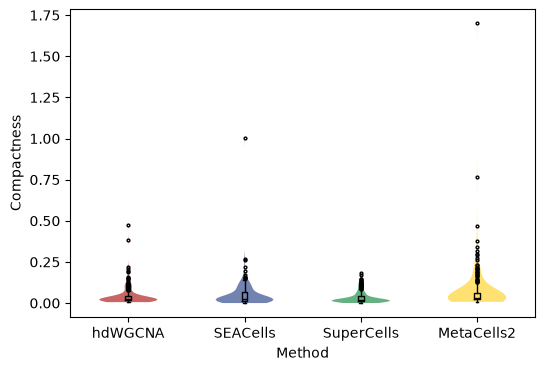

In [24]:
violin_by_method(metrics_df, "compactness", "Compactness")
plt.show()

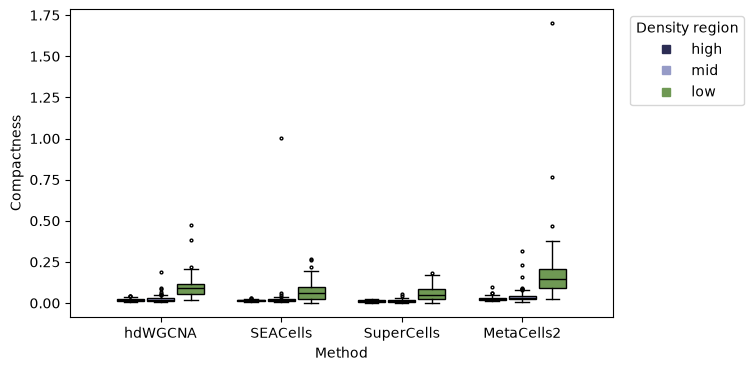

In [25]:
def box_by_region(df: pl.DataFrame, value: str, ylabel: str) -> plt.Axes:
    _, ax = plt.subplots(figsize=(7, 4))
    width = 0.25
    for j, region in enumerate(regions):
        data = [
            df.filter((pl.col("method") == m) & (pl.col("region") == region))[
                value
            ].to_numpy()
            for m in methods
        ]
        positions = np.arange(len(methods)) + (j - 1) * width
        # a method with no meta cells in a region gets no box
        keep = [i for i, d in enumerate(data) if d.size > 0]
        bp = ax.boxplot(
            [data[i] for i in keep],
            positions=positions[keep],
            widths=width * 0.9,
            patch_artist=True,
            flierprops={"markersize": 2},
            medianprops={"color": "black"},
        )
        for box in bp["boxes"]:
            box.set_facecolor(region_colours[region])
        ax.plot([], [], "s", color=region_colours[region], label=region)
    ax.set_xticks(range(len(methods)), methods)
    ax.set_xlabel("Method")
    ax.set_ylabel(ylabel)
    ax.legend(title="Density region", bbox_to_anchor=(1.02, 1), loc="upper left")
    return ax


box_by_region(metrics_df, "compactness", "Compactness")
plt.show()

#### Separation plots

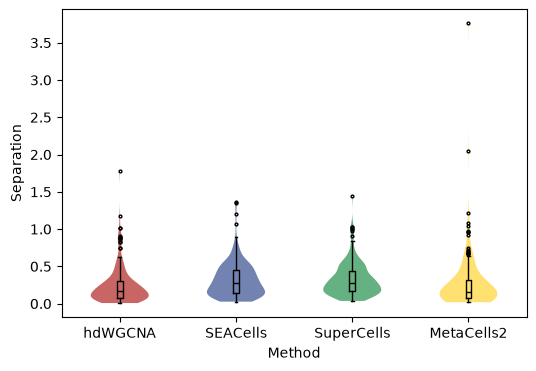

In [26]:
violin_by_method(metrics_df, "separation", "Separation")
plt.show()

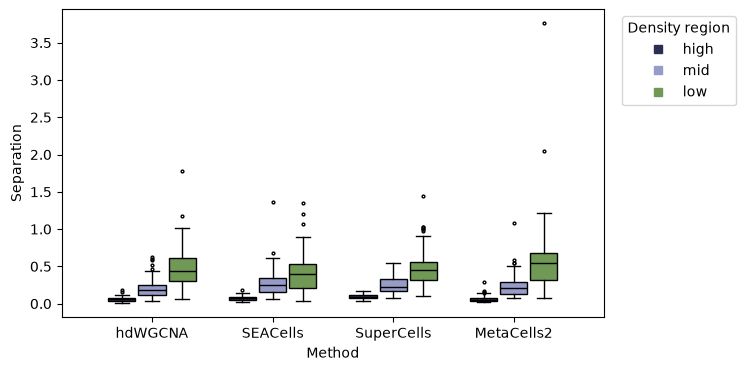

In [27]:
box_by_region(metrics_df, "separation", "Separation")
plt.show()

Based on this, we can conclude the following:

- Purity is VERY similar across the methods (for this data set).
- At matched K (~250 meta cells), SuperCells achieves the lowest median
  compactness, ahead of hdWGCNA and SEACells. Separation is comparable
  between SuperCells and SEACells, with hdWGCNA noticeably lower.
- The methods differ markedly in where they place meta cells. SEACells
  assigns about half of its meta cells to low density regions versus under a
  quarter for hdWGCNA (and MetaCells2) and about 40% for SuperCells,
  consistent with its kernel archetypal formulation seeking out
  underrepresented states.
- Method choice should reflect the downstream question. For tight
  aggregation in dense regions (e.g., bulk-like pseudo-replicates of common
  cell types), SuperCells is efficient and effective. For preserving rare
  populations or transitioning states (e.g., differentiation trajectories),
  SEACells' rare-state bias is desirable, with the trade-off of more
  heterogeneous meta cells in those regions. hdWGCNA is fast and simple but
  assignments overlap more in embedding space.

### Scoring external assignments

`calc_manifold_metrics()` only scores meta cells that bixverse generated. If
you have an assignment from somewhere else (SEACells in Python, a different
parameter set, a clustering you want to compare against), you can score it in
an existing diffusion map with `calc_meta_cell_compactness()` and
`calc_meta_cell_separation()`. They take the diffusion map and one label per
row; `None` marks cells that are not part of any meta cell. The rows of the
diffusion map follow the kept cells of the parent object (`sc.cells_to_keep`
order), so that is what the labels need to be aligned to.

To keep it self-contained, we pretend the SEACells assignment came from an
outside tool as a cell to meta cell table, and compare it against a random
assignment with the same meta cell sizes.

In [28]:
dcs = seacells.other_data["dcs"]
cell_ids = sc.obs(cols=["cell_idx", "cell_id"])

# what an external tool would hand you: cell id -> meta cell
external = (
    seacells.obs(cols=["meta_cell_id", "original_cell_idx"])
    .explode("original_cell_idx")
    .join(cell_ids, left_on="original_cell_idx", right_on="cell_idx")
    .select("cell_id", "meta_cell_id")
)

assignment = (
    sc.obs(cols=["cell_id"], filtered=True)
    .join(external, on="cell_id", how="left", maintain_order="left")["meta_cell_id"]
    .to_list()
)

rng = np.random.default_rng(42)
assigned = [i for i, x in enumerate(assignment) if x is not None]
random_assignment = list(assignment)
for i, j in zip(assigned, rng.permutation(assigned), strict=True):
    random_assignment[i] = assignment[j]


def score(assignment: list[str | None], name: str) -> pl.DataFrame:
    return (
        bv.metacells.calc_meta_cell_compactness(dcs, assignment)
        .join(bv.metacells.calc_meta_cell_separation(dcs, assignment), on="meta_cell")
        .with_columns(assignment=pl.lit(name))
    )


external_df = pl.concat(
    [score(assignment, "SEACells"), score(random_assignment, "random")]
)

external_df.group_by("assignment", maintain_order=True).agg(
    median_compactness=pl.col("compactness").median(),
    median_separation=pl.col("separation").median(),
)

assignment,median_compactness,median_separation
str,f32,f32
"""SEACells""",0.023736,0.270859
"""random""",0.746713,0.231275


The SEACells numbers match what `calc_manifold_metrics()` wrote into the obs
table above:

In [29]:
seacells_obs = seacells.obs(cols=["meta_cell_id", "compactness", "separation"])
check = external_df.filter(pl.col("assignment") == "SEACells").join(
    seacells_obs, left_on="meta_cell", right_on="meta_cell_id", suffix="_obs"
)

assert check.height == seacells_obs.height
assert np.allclose(check["compactness"], check["compactness_obs"])
assert np.allclose(check["separation"], check["separation_obs"])

The random assignment is the floor: meta cells that are spread across the
manifold have a large variance and their centroids all collapse towards the
middle, so compactness goes up and separation goes down.

## Working with the MetaCells class

This is where the in-memory representation pays off. HVG selection, PCA,
neighbour graphs and embeddings on a few hundred meta cells take seconds and
do not touch the Rust binary files on disk. We will just take forward
SEACells here, but the methods below work across all of `MetaCells`.

### HVGs and PCA

The same HVG and PCA functions you know from single cells work here...

In [30]:
bv.pp.find_hvg(seacells, hvg_no=2000)

bv.pp.calculate_pca(seacells, no_pcs=30)

### Neighbours, clustering and UMAP

And also the same interfaces for neighbours, (Leiden) clustering and UMAP can
be used here. The UMAP reuses the kNN graph from `find_neighbours`.

In [31]:
bv.graph.find_neighbours(
    seacells, neighbours_params=NeighboursParams(k=10, knn_method="exhaustive")
)

bv.graph.find_clusters(seacells, res=1.0, name="leiden_clusters")

bv.embed.umap(seacells)

seacells

MetaCells(
  method=seacell, merged=False,
  meta_cells=250, genes=12464,
  cells_aggregated=6881, source_obs_rows=6881,
  hvg=True, pca=True, embeddings=['umap'],
  knn=True, graph=True, residuals=False,
  stale=none
)

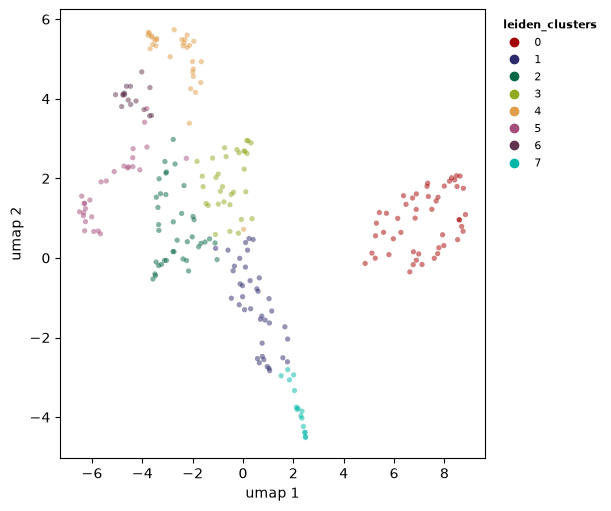

In [32]:
bv.pl.embedding_plot(
    seacells,
    "umap",
    "leiden_clusters",
    discrete=True,
)
plt.show()

The plot is much sparser than the equivalent UMAP on the original cells,
which is the point: each dot is a denoised aggregate of ~27 cells on average
(6881 cells over 250 SEACells), and the
structure that survives aggregation is the structure that's robust to
sparsity.

### Co-expression module detection on meta cells

Meta cells compress information and reduce sparsity. That makes them ideal
for co-expression module detection methods, and the SCENIC implementation
within bixverse,
[akin to the single cell version](bag_of_genes_single_cells.ipynb), also runs
on `MetaCells`.

We need the human TF list from the Aerts lab (`allTFs_hg38.txt` from their
[cisTarget resources](https://resources.aertslab.org/cistarget/tf_lists/)).
The Python package does not ship a copy yet, so we fetch it from there. The
genes in this data set are symbols already, so we only drop the TFs that are
not in the data.

In [33]:
tf_url = "https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt"
with urllib.request.urlopen(tf_url) as f:
    tf_symbols = f.read().decode().split()

genes = set(seacells.var(cols=["gene_id"])["gene_id"].to_list())
tf_ids = [tf for tf in tf_symbols if tf in genes]

len(tf_ids)

1282

Let's run this quickly...

In [34]:
scenic_res = bv.pathways.scenic_grn(
    seacells,
    tf_ids,
    scenic_params=ScenicParams(
        learner_type="randomforest",
        gene_batch_size=64,
        # due to the small data set size, we should set 'min_samples_leaf'
        # lower than for a massive single cell data set
        learner_params=ScenicRandomForestDefaults(min_samples_leaf=10),
    ),
    verbose=True,
)

Quantised TF store (n: 1_282) in: 794.92µs
Computing gene loadings: 12464 genes, 250 subsampled cells, 50 components
Clustering 12464 genes into 195 groups
Extracted 12464 target columns in 3.27ms
Running SCENIC (RandomForest, in-memory) on 12464 genes (1282 TFs, 250 cells, 195 batches of up to 64)


  Progress: 10% (20 / 195 batches, 2.93s)


  Progress: 20% (39 / 195 batches, 5.36s)


  Progress: 30% (59 / 195 batches, 7.69s)


  Progress: 40% (78 / 195 batches, 10.70s)


  Progress: 50% (98 / 195 batches, 12.72s)


  Progress: 60% (117 / 195 batches, 14.59s)


  Progress: 70% (137 / 195 batches, 16.54s)


  Progress: 80% (156 / 195 batches, 18.38s)


  Progress: 90% (176 / 195 batches, 20.24s)


  Progress: 100% (195 / 195 batches, 21.79s)
SCENIC (RandomForest, in-memory) GRN inference complete in 21.95s


In [35]:
scenic_res = bv.pathways.identify_tf_to_genes(scenic_res, n_sd=2.0, verbose=True)

scenic_res = bv.pathways.tf_to_genes_correlations(scenic_res, seacells, verbose=True)

# no motif filter here, so the leading edge column does not exist yet
tf_to_gene = bv.pathways.build_regulons(scenic_res, use_leading_edge=False)

len(tf_to_gene)

Calculating pairwise correlations between the genes of interest for meta cells.
Calculated pairwise correlations for meta cells in 57.86ms


563

In a proper situation we would filter down the TF to gene associations via
motifs, see the details in the
[bag of genes vignette](bag_of_genes_single_cells.ipynb). We will skip this
step for now and just run AUCell to show how it works. Which statistic you
get is controlled by `AucellParams`. The default is `"recovery"`, the
original AUCell recovery curve, which is what SCENIC uses. `"wilcox"`
(Mann-Whitney AUC over the full ranking) and `"ap"` (average precision) are
the other two options.

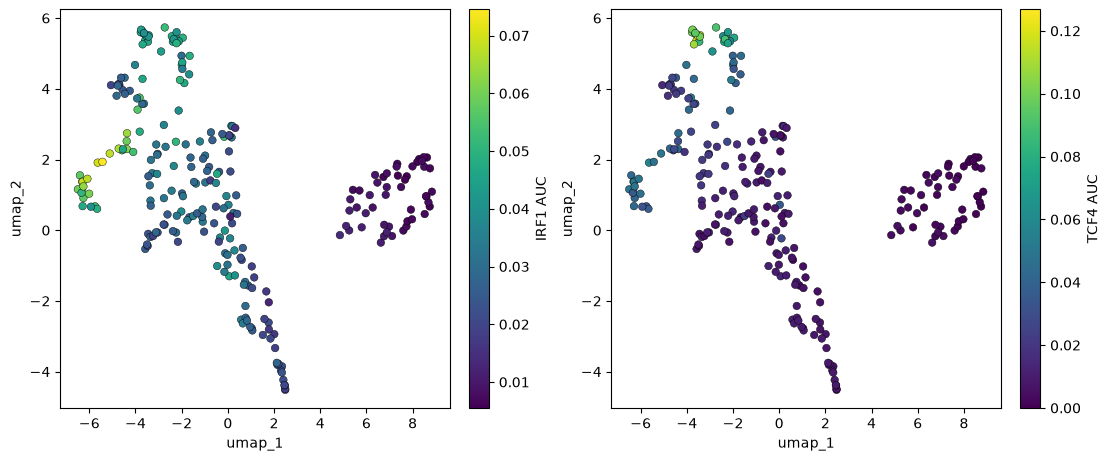

In [36]:
auc_res = bv.pathways.aucell(seacells, tf_to_gene)

umap = seacells.cache.embeddings["umap"]
auc_df = bv.pathways.get_data(auc_res, columns=["IRF1", "TCF4"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, tf in zip(axes, ["IRF1", "TCF4"], strict=True):
    points = ax.scatter(
        umap[:, 0],
        umap[:, 1],
        c=auc_df[tf].to_numpy(),
        cmap="viridis",
        s=30,
        edgecolors="black",
        linewidths=0.3,
    )
    fig.colorbar(points, ax=ax, label=f"{tf} AUC")
    ax.set_xlabel("umap_1")
    ax.set_ylabel("umap_2")
plt.show()

### Consensus NMF on meta cells

The same argument applies to matrix factorisation, and here compression buys
you something concrete. Consensus NMF
([Kotliar, et al.](https://elifesciences.org/articles/43803)) fits `n_runs`
NMFs, pools their components, drops the ones sitting on their own, clusters
the survivors and takes the median of each cluster. What survives is the
programme structure the restarts agree on. The catch on raw single cells is
memory: every restart is dense, and they all live at once. On a few thousand
meta cells rather than a few hundred thousand cells, `n_runs=50` is
unremarkable. This is the path where consensus NMF is genuinely affordable.

Start by picking `k`. `nmf_k_sweep()` runs the consensus step across a range
of ranks and reports stability against reconstruction error, keeping no
factors.

In [37]:
mc_k_sweep = bv.nmf.nmf_k_sweep(
    seacells,
    range(2, 13),
    n_runs=10,
    nmf_consensus_params=NmfConsensusParams(density_threshold=2.0),
)

with pl.Config(tbl_rows=11):
    print(mc_k_sweep)

NmfKSweepResult (consensus NMF k sweep)
  Source class:     MetaCells
  k range:          2 to 12
  No runs per k:    10
  Most stable k:    3 (stability = 0.9998)

shape: (11, 8)
┌─────┬───────────┬────────────┬─────────────┬─────────────┬───────────┬─────────────┬─────────────┐
│ k   ┆ stability ┆ best_error ┆ median_erro ┆ consensus_f ┆ n_dropped ┆ n_empty_clu ┆ n_converged │
│ --- ┆ ---       ┆ ---        ┆ r           ┆ ailed       ┆ ---       ┆ sters       ┆ ---         │
│ i64 ┆ f64       ┆ f64        ┆ ---         ┆ ---         ┆ i64       ┆ ---         ┆ i64         │
│     ┆           ┆            ┆ f64         ┆ bool        ┆           ┆ i64         ┆             │
╞═════╪═══════════╪════════════╪═════════════╪═════════════╪═══════════╪═════════════╪═════════════╡
│ 2   ┆ 0.999677  ┆ 0.164708   ┆ 0.164721    ┆ false       ┆ 0         ┆ 0           ┆ 10          │
│ 3   ┆ 0.999824  ┆ 0.132091   ┆ 0.132101    ┆ false       ┆ 0         ┆ 0           ┆ 10          │
│ 4   ┆ 0.98

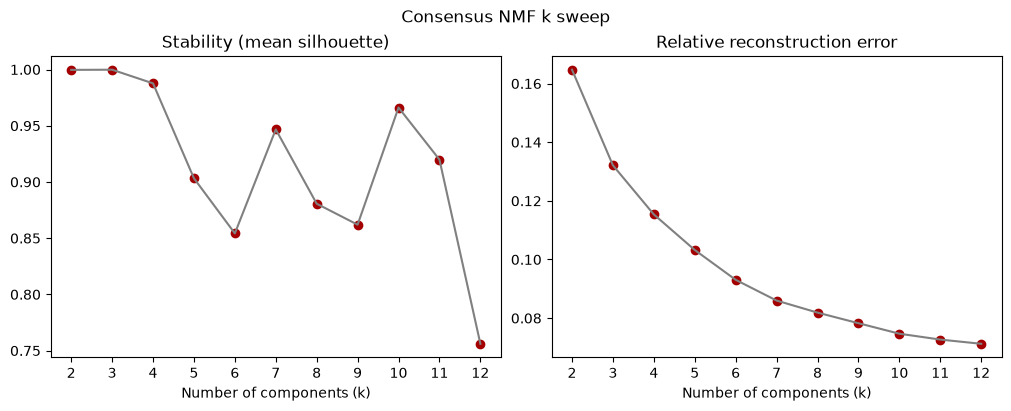

In [38]:
sweep = mc_k_sweep.frame.filter(pl.col("stability").is_not_null())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, col, title in zip(
    axes,
    ["stability", "median_error"],
    ["Stability (mean silhouette)", "Relative reconstruction error"],
    strict=True,
):
    ax.plot(sweep["k"], sweep[col], color="grey")
    ax.scatter(sweep["k"], sweep[col], color=bv.pl.bx_colors("main", n=1)[0])
    ax.set_xticks(sweep["k"].to_list())
    ax.set_xlabel("Number of components (k)")
    ax.set_title(title)
fig.suptitle("Consensus NMF k sweep")
plt.show()

The usual rule is to take the last `k` before stability falls away, while the
error curve is still coming down. Here it does not fall away so much as
bounce: past the trivially stable `k = 2` to `4`, stability dips and
recovers, which says the meta cells support several plausible ranks rather
than one obvious answer. It peaks again at 7 and 10. We will go with the
smaller rank for this vignette, but in reality it might be worth exploring
both.

In [39]:
mc_nmf = bv.nmf.consensus_nmf(
    seacells,
    7,
    n_runs=10,
    nmf_consensus_params=NmfConsensusParams(density_threshold=2.0),
)

mc_nmf

ConsensusNmfResult (consensus HALS NMF)
  Source class:     MetaCells
  No genes:         2000
  No cells:         250
  No components:    7
  No runs:          10
  Stability:        0.9502
  Relative error:   0.08597
  Dropped:          0 / 70 components
  Preprocessing:    none

`get_stability()` gives you the diagnostics: the mean silhouette of the
clusters, the relative reconstruction errors, and a row per pooled component
recording where it landed.

In [40]:
mc_nmf_diag = bv.nmf.get_stability(mc_nmf)

print(f"stability: {mc_nmf_diag['stability']:.3f}")

mc_nmf_diag["cluster_sizes"]

stability: 0.950


cluster,n
i64,i64
0,10
1,10
2,8
3,10
4,12
5,10
6,10


With 10 restarts, a cluster of 10 is a programme every run found. A thin one
is a programme only some initialisations saw.

`w` (genes x k) and `h` (k x meta cells) come back in the same shape the
single-run `nmf()` gives you, so the activations drop straight onto the UMAP:

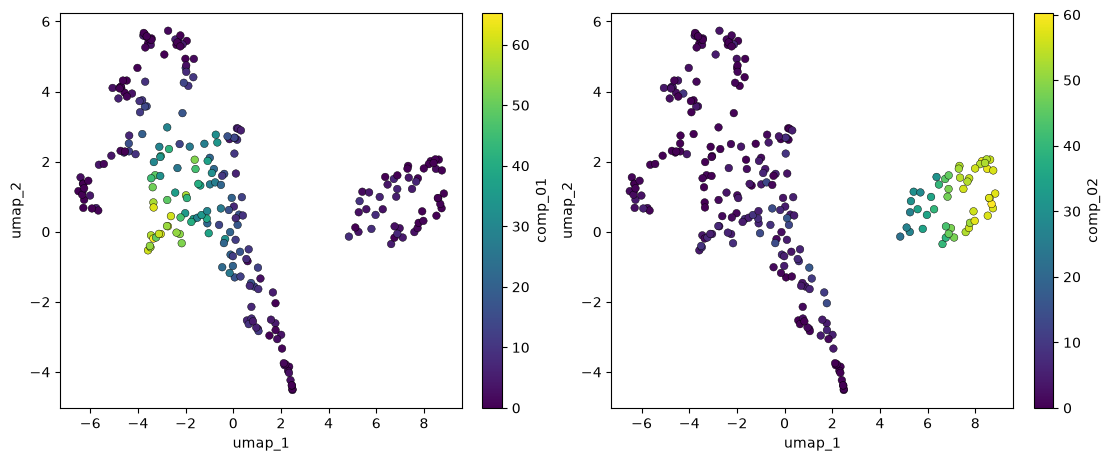

In [41]:
mc_h = bv.nmf.get_data(mc_nmf)

# one row per meta cell, in the order of the UMAP rows
assert (mc_h["meta_cell_idx"].to_numpy() == np.arange(seacells.n_cells)).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, comp in zip(axes, ["comp_01", "comp_02"], strict=True):
    points = ax.scatter(
        umap[:, 0],
        umap[:, 1],
        c=mc_h[comp].to_numpy(),
        cmap="viridis",
        s=30,
        edgecolors="black",
        linewidths=0.3,
    )
    fig.colorbar(points, ax=ax, label=comp)
    ax.set_xlabel("umap_1")
    ax.set_ylabel("umap_2")
plt.show()

To read off what a programme is, rank the genes by their loading in `w`:

In [42]:
mc_w = bv.nmf.get_w(mc_nmf)

top_genes = {
    comp: mc_w.sort(comp, descending=True)["gene_id"].head(10).to_list()
    for comp in ["comp_01", "comp_02", "comp_03"]
}

top_genes

{'comp_01': ['MPO',
  'ATP8B4',
  'AZU1',
  'FNDC3B',
  'LRMDA',
  'KCNQ5',
  'PLCB1',
  'ELANE',
  'CSF3R',
  'EREG'],
 'comp_02': ['XACT',
  'RPL12',
  'ZNF385D',
  'RYR3',
  'S100A6',
  'GAPDH',
  'S100A4',
  'MIF',
  'LRBA',
  'HBB'],
 'comp_03': ['LYZ',
  'CST3',
  'SAMHD1',
  'SLC8A1',
  'AFF3',
  'LGALS1',
  'S100A4',
  'RAB11FIP1',
  'S100A6',
  'PIK3R5']}

## Pseudo-bulking

Pseudo-bulks are conceptually adjacent but solve a different problem. Where
meta cells are dense aggregates designed to feed into co-expression and
archetype methods, pseudo-bulks are coarse summaries (one bulk per
sample-by-cluster combination, say) used as input to bulk-style DGE tools
such as limma-voom, edgeR or DESeq2 to get around pseudo-replication problems
and p-value inflation in cell-based DGEs, see
[Zimmerman et al.](https://www.nature.com/articles/s41467-021-21038-1)

`get_pseudobulked` takes a dict of cell IDs (or indices) and returns either a
dense array or a sparse CSR matrix. With `assay="raw"` it sums raw counts
(what bulk DGE tools expect); with `assay="norm"` it averages normalised
counts.

In [43]:
cl_df = sc.obs(cols=["leiden", "cell_id"], filtered=True)
cell_list = {
    str(k[0]): g["cell_id"].to_list()
    for k, g in cl_df.sort("leiden").group_by("leiden", maintain_order=True)
}

pb = bv.de.get_pseudobulked(sc, cell_list, return_format="sparse", assay="raw")

pb.counts.shape

(14, 12464)

The returned matrix has one row per group and one column per gene. From here
the standard bulk DGE pipeline applies: transpose it and hand it to
`bv.de.run_edger_ql()`, in Rust, no edgeR needed. (The limma-voom twin is not
ported to Python yet.)

## Clean up

In [44]:
tempdir_cd34.cleanup()